## Ćwiczenie 9: Analiza Widmowa (FFT) - Blok 1 (ROZWIĄZANIA)
**Cel:** Zrozumienie różnicy między dziedziną przestrzenną (piksele) a dziedziną częstotliwości (fale). Wykonanie pierwszej Transformaty Fouriera i zaprojektowanie podstawowego filtru dolnoprzepustowego.

#### Wprowadzenie teoretyczne
Ten plik zawiera kompletne rozwiązania do Bloku 1.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color

plt.rcParams['figure.figsize'] = (12, 6)

#### Krok 1: Wczytanie obrazu medycznego
Wykorzystamy przekrój z rezonansu magnetycznego (MRI), który zawiera zarówno łagodne przejścia (tkanka), jak i bardzo ostre krawędzie (czaszka).

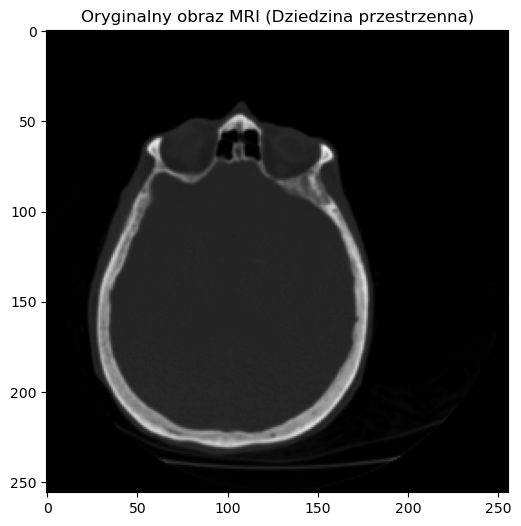

In [22]:
# Wczytujemy 10-ty przekrój skanu MRI
mri_image = data.brain()[1, :, :]

plt.title('Oryginalny obraz MRI (Dziedzina przestrzenna)')
plt.imshow(mri_image, cmap='gray')
plt.show()

#### Krok 2: Przejście w dziedzinę częstotliwości (FFT)
**Zadanie:** Użyj biblioteki NumPy do obliczenia dwuwymiarowej Transformaty Fouriera (`np.fft.fft2`), a następnie przesuń środek układu współrzędnych (`np.fft.fftshift`), aby zerowe częstotliwości znalazły się w centrum obrazu.

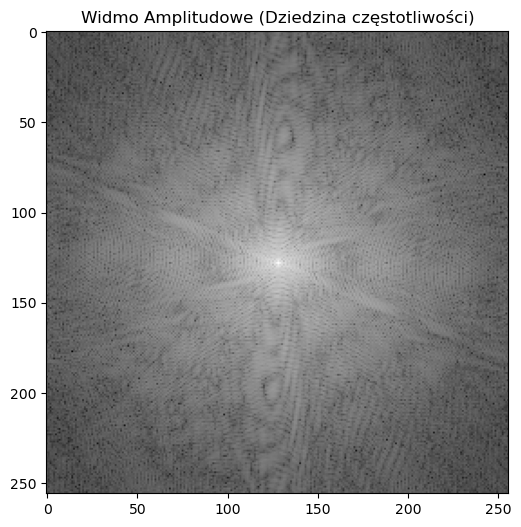

In [25]:
# ROZWIĄZANIE:
fft_result = np.fft.fft2(mri_image)
fft_shifted = np.fft.fftshift(fft_result)

# FFT zwraca liczby ZESPOLONE. Aby je wyświetlić, musimy "wyciągnąć" ich moduł (amplitudę).
# Ponadto dynamika wartości jest bardzo duża, konieczne jest więc użycie skali logarytmicznej, w przeciwnym razie zobaczymy tylko jeden biały punkt.

# ROZWIĄZANIE:
magnitude_spectrum = np.log(1 + np.abs(fft_shifted))

plt.title('Widmo Amplitudowe (Dziedzina częstotliwości)')
plt.imshow(magnitude_spectrum, cmap='gray')
plt.show()

#### Krok 3: Eksperyment 1 – Filtr dolnoprzepustowy (Low-Pass Filter)
Sprawdźmy, co się stanie, gdy wytniemy (wyzerujemy) z widma wszystkie wysokie częstotliwości (pozostawiając tylko fale ze środka).

**Zadanie:** Przeanalizuj kod tworzący okrągłą maskę. Następnie wykonaj Odwrotną Transformatę Fouriera (`ifft2`), aby odzyskać obraz z odfiltrowanego widma.

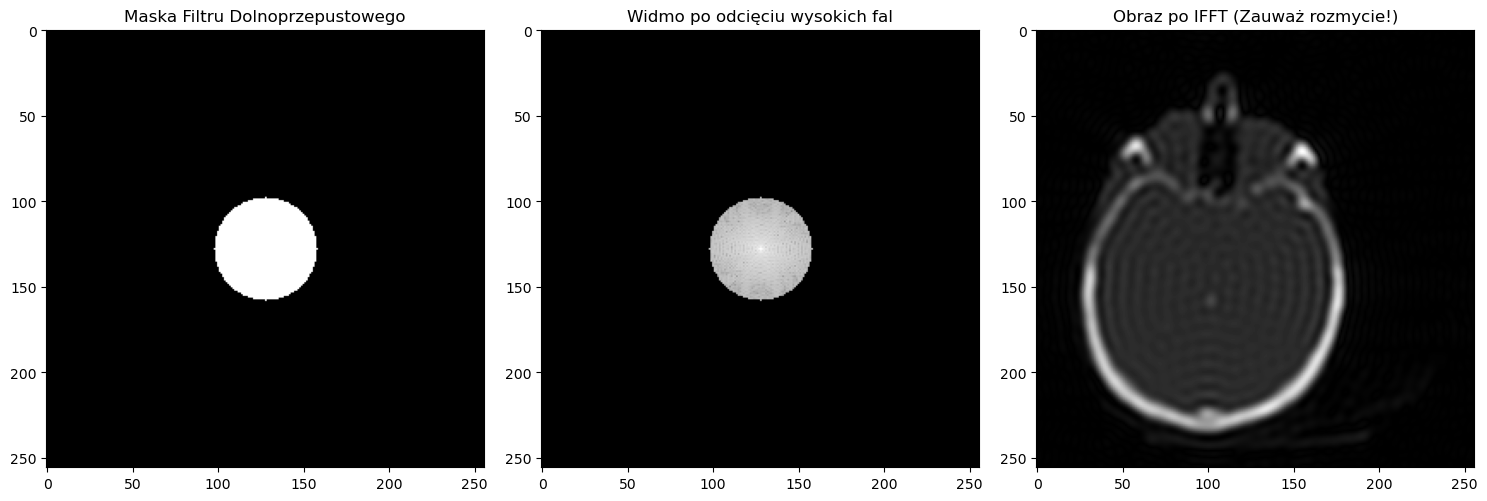

In [13]:
# 1. Tworzymy siatkę współrzędnych i okrągłą maskę na środku obrazu
rows, cols = mri_image.shape
center_row, center_col = rows // 2, cols // 2

Y, X = np.ogrid[:rows, :cols]
distance_from_center = np.sqrt((X - center_col)**2 + (Y - center_row)**2)

# Zostawiamy tylko fale o promieniu mniejszym niż 30 pikseli od centrum
radius = 30
low_pass_mask = distance_from_center <= radius

# 2. Wymnażamy nasze widmo (fft_shifted) przez maskę - ucinamy brzegi widma
filtered_fft_shifted = fft_shifted * low_pass_mask

# ROZWIĄZANIE:
fft_ishift = np.fft.ifftshift(filtered_fft_shifted)
image_reconstructed = np.fft.ifft2(fft_ishift)

# Wyciągamy rzeczywistą część zrekonstruowanego obrazu (odrzucamy ewentualne ułamki zespolone z błędów numerycznych)
image_reconstructed = np.abs(image_reconstructed)

# --- WIZUALIZACJA --- 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(low_pass_mask, cmap='gray')
axes[0].set_title('Maska Filtru Dolnoprzepustowego')
axes[1].imshow(np.log(1 + np.abs(filtered_fft_shifted)), cmap='gray')
axes[1].set_title('Widmo po odcięciu wysokich fal')
axes[2].imshow(image_reconstructed, cmap='gray')
axes[2].set_title('Obraz po IFFT (Zauważ rozmycie!)')
plt.tight_layout()
plt.show()